In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip -q -o /content/drive/MyDrive/tlp25_IRP/npy_files.zip -d /content/

In [3]:
!pip install pandas==2.3.3 livelossplot torchinfo -q

import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import glob
import sys
import pandas as pd
from sklearn.model_selection import train_test_split
from torchinfo import summary
import random
from sklearn.metrics import r2_score
from torch.utils.data import DataLoader
import torch.nn as nn
from livelossplot import PlotLosses

sys.path.append("/content/drive/MyDrive/tlp25_IRP/Modelling")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 135.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 626.0/626.0 kB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 123.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.2/86.2 kB 10.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipython==7.34.0, but you have ipython 9.16.1 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.


In [4]:
sys.path.append("/content/drive/MyDrive/tlp25_IRP/Modelling")

from FiLm_UNET import MultiHeadUNET
from Plot_dataset import plot_dataset
from get_norm_stats import get_normalization_stats
from FiLM_Dataset import UHSDataset, transform_dataset

In [5]:
def set_device(device="cpu", idx=0):
    if device != "cpu":
        if torch.cuda.device_count() > idx and torch.cuda.is_available():
            print("Cuda installed! Running on GPU {} {}!".format(idx, torch.cuda.get_device_name(idx)))
            device="cuda:{}".format(idx)
        elif torch.cuda.device_count() > 0 and torch.cuda.is_available():
            print("Cuda installed but only {} GPU(s) available! Running on GPU 0 {}!".format(torch.cuda.device_count(), torch.cuda.get_device_name()))
            device="cuda:0"
        else:
            device="cpu"
            print("No GPU available! Running on CPU")
    return device

device = set_device("cuda")

def set_seed(seed=42):
    """
    Set the random seed for reproducibility.

    Parameters:
    ----------
    seed (int): The seed value to set for random number generation.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.enabled = True

    return True

Cuda installed! Running on GPU 0 NVIDIA A100-SXM4-40GB!


In [6]:
npy_file_dir = "/content/content/drive/MyDrive/tlp25_IRP/npy_files/"

site_dirs = sorted(os.listdir(npy_file_dir))

train_files, val_test_files = train_test_split(site_dirs, test_size=0.3, random_state=42)
val_files, test_files = train_test_split(val_test_files, test_size = 0.5, random_state=42)

In [7]:
print(train_files)

['Site_500', 'Site_579', 'Site_819', 'Site_462', 'Site_9', 'Site_562', 'Site_166', 'Site_446', 'Site_285', 'Site_458', 'Site_510', 'Site_688', 'Site_1006', 'Site_4', 'Site_236', 'Site_824', 'Site_132', 'Site_456', 'Site_536', 'Site_655', 'Site_275', 'Site_922', 'Site_25', 'Site_748', 'Site_438', 'Site_553', 'Site_264', 'Site_881', 'Site_821', 'Site_822', 'Site_219', 'Site_957', 'Site_472', 'Site_441', 'Site_535', 'Site_595', 'Site_410', 'Site_939', 'Site_1004', 'Site_2', 'Site_580', 'Site_618', 'Site_356', 'Site_54', 'Site_478', 'Site_805', 'Site_604', 'Site_45', 'Site_615', 'Site_956', 'Site_842', 'Site_498', 'Site_570', 'Site_62', 'Site_739', 'Site_70', 'Site_206', 'Site_265', 'Site_431', 'Site_76', 'Site_250', 'Site_924', 'Site_130', 'Site_193', 'Site_331', 'Site_616', 'Site_402', 'Site_549', 'Site_497', 'Site_1037', 'Site_524', 'Site_18', 'Site_59', 'Site_34', 'Site_509', 'Site_800', 'Site_586', 'Site_878', 'Site_782', 'Site_1', 'Site_859', 'Site_403', 'Site_344', 'Site_738', 'Site

In [8]:
stats_dict = get_normalization_stats(train_dataset=train_files)

{'min_fcmip': 15634616.0, 'max_fcmip': 21247800.0, 'min_fcmpr': 0.0, 'max_fcmpr': 21179.091796875, 'min_fcmir': 0.0, 'max_fcmir': 25313.69921875, 'min_pressure': np.float32(96.28905), 'max_pressure': np.float32(104.03392)}


In [9]:
!ls content/drive/MyDrive/tlp25_IRP/

npy_files


In [10]:
import pickle
with open('/content/drive/MyDrive/tlp25_IRP/norm_stats.pkl', 'wb') as f:
    pickle.dump(stats_dict, f)

In [11]:
transform = transform_dataset
dir = '/content/content/drive/MyDrive/tlp25_IRP/npy_files/'
train_dataset = UHSDataset(train_files, transform=transform, norm_stats=stats_dict, dir=dir)
val_dataset = UHSDataset(val_files, transform=transform, norm_stats=stats_dict, dir=dir)
test_dataset = UHSDataset(test_files, transform=transform, norm_stats=stats_dict, dir=dir)

In [12]:
!ls content/drive/MyDrive/tlp25_IRP/npy_files/norm_stats*

ls: cannot access 'content/drive/MyDrive/tlp25_IRP/npy_files/norm_stats*': No such file or directory


In [13]:
%timeit train_dataset[0]
%timeit train_dataset[949]

12.3 ms ± 170 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)
12.2 ms ± 198 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [14]:
model = MultiHeadUNET(in_channels=2, grid_out_channels=2, scalar_out_channels=3).to(device)
grid_input = torch.ones(1, 2, 12, 61, 61).to(device)
cond_input = torch.randn(1, 6).to(device)
spatial, rate = model(grid_input, cond_input)
print("spatial shape:", spatial.shape)   # (1, 3, 12, 61, 61)
print("rate shape:", rate.shape)         # (1, 2)

summary(model, input_data=[grid_input, cond_input])

spatial shape: torch.Size([1, 2, 12, 61, 61])
rate shape: torch.Size([1, 3])


Layer (type:depth-idx)                   Output Shape              Param #
MultiHeadUNET                            [1, 2, 12, 61, 61]        --
├─Encoder: 1-1                           [1, 64, 16, 64, 64]       --
│    └─FiLMConvBlock: 2-1                [1, 64, 16, 64, 64]       --
│    │    └─Conv3d: 3-1                  [1, 64, 16, 64, 64]       3,520
│    │    └─BatchNorm3d: 3-2             [1, 64, 16, 64, 64]       128
│    │    └─FiLM: 3-3                    [1, 64, 1, 1, 1]          17,408
│    │    └─GELU: 3-4                    [1, 64, 16, 64, 64]       --
│    └─FiLMConvBlock: 2-2                [1, 64, 16, 64, 64]       --
│    │    └─Conv3d: 3-5                  [1, 64, 16, 64, 64]       110,656
│    │    └─BatchNorm3d: 3-6             [1, 64, 16, 64, 64]       128
│    │    └─FiLM: 3-7                    [1, 64, 1, 1, 1]          17,408
│    │    └─GELU: 3-8                    [1, 64, 16, 64, 64]       --
│    └─MaxPool3d: 2-3                    [1, 64, 8, 32, 32]        

In [15]:
def relative_l2_loss(pred, target, eps=1e-8):
  batch_size = pred.shape[0]
  pred_flat = pred.reshape(batch_size, -1)
  target_flat = target.reshape(batch_size, -1)
  num = torch.norm(target_flat - pred_flat, p=2, dim=1)
  denom = torch.norm(target_flat, p=2, dim=1) + eps
  return (num/denom).mean()


def combined_loss(grid_pred, grid_target, scalar_pred, scalar_target,
                   grid_criterion, scalar_criterion, scalar_weight=1.0):
  grid_loss = grid_criterion(grid_pred, grid_target)
  scalar_loss = scalar_criterion(scalar_pred, scalar_target)
  combined_loss_val = grid_loss + scalar_loss*scalar_weight
  return combined_loss_val, grid_loss, scalar_loss


In [23]:
set_seed(42)
p = 0.6
lr = 5e-4
batch_size = 32
num_workers = 4
wd = 1e-6
epochs = 200

scalar_criterion = nn.MSELoss()
grid_criterion = relative_l2_loss
scalar_weight = 1.0

optimiser = torch.optim.Adam(params=model.parameters(), lr=lr, weight_decay=wd)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=epochs, eta_min=1e-6)

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
valid_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)



In [17]:
def plume_saturation_error_torch(S, S_hat, threshold=0.01):
    mask = (S > threshold) | (S_hat.abs() > threshold)
    denom = mask.sum()
    if denom == 0:
        return torch.tensor(0.0, device=S.device, dtype=S.dtype)
    numerator = (mask * (S - S_hat).abs()).sum()
    return numerator / denom

def relative_pressure_error_torch(P, P_hat):
    n_T = P.shape[0]
    n_omega = P[0].numel()

    spatial_axes = tuple(range(1, P.dim()))
    P_max_per_t = torch.amax(P, dim=spatial_axes, keepdim=True)

    abs_error = (P - P_hat).abs()
    relative_error = abs_error / P_max_per_t

    return relative_error.sum() / (n_omega * n_T)


In [18]:
def train(model, optimizer, grid_criterion, scalar_criterion, data_loader, scalar_weight=1.0):
    model.train()
    train_loss = 0
    train_grid_loss = 0
    train_scalar_loss = 0

    for input_grid, cond, spatial_target, rate_target in data_loader:
        input_grid = input_grid.to(device)
        cond = cond.to(device)
        spatial_target = spatial_target.to(device)
        rate_target = rate_target.to(device)

        optimizer.zero_grad()

        spatial_pred, rate_pred = model(input_grid, cond)

        loss, grid_loss, scalar_loss_val = combined_loss(
            spatial_pred, spatial_target, rate_pred, rate_target,
            grid_criterion, scalar_criterion, scalar_weight=scalar_weight
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * input_grid.size(0)
        train_grid_loss += grid_loss.item() * input_grid.size(0)
        train_scalar_loss += scalar_loss_val.item() * input_grid.size(0)

    n = len(data_loader.dataset)
    train_loss = train_loss / n
    grid_loss_f = train_grid_loss / n
    scal_loss = train_scalar_loss / n

    return train_loss, grid_loss_f, scal_loss

def valid(model, grid_criterion, scalar_criterion, data_loader, val_dataset, scalar_weight=1.0):
    model.eval()
    valid_loss = 0
    valid_grid_loss = 0
    valid_scalar_loss = 0

    all_sat_true, all_sat_pred = [], []
    all_press_true, all_press_pred = [], []
    all_rate_true, all_rate_pred = [], []

    with torch.no_grad():
        for input_grid, cond, spatial_target, rate_target in data_loader:
            input_grid = input_grid.to(device)
            cond = cond.to(device)
            spatial_target = spatial_target.to(device)
            rate_target = rate_target.to(device)

            spatial_pred, rate_pred = model(input_grid, cond)

            loss, grid_loss, scalar_loss_val = combined_loss(
                spatial_pred, spatial_target, rate_pred, rate_target,
                grid_criterion, scalar_criterion, scalar_weight=scalar_weight
            )
            valid_loss += loss.item() * input_grid.size(0)
            valid_grid_loss += grid_loss.item() * input_grid.size(0)
            valid_scalar_loss += scalar_loss_val.item() * input_grid.size(0)

            all_sat_true.append(spatial_target[:, 0].cpu())
            all_sat_pred.append(spatial_pred[:, 0].cpu())

            all_press_true.append(spatial_target[:, 1].cpu())
            all_press_pred.append(spatial_pred[:, 1].cpu())

            all_rate_true.append(rate_target.cpu())
            all_rate_pred.append(rate_pred.cpu())

        n = len(data_loader.dataset)
        valid_loss = valid_loss / n
        grid_loss_f = valid_grid_loss / n
        scal_loss = valid_scalar_loss / n

        rand_int = torch.randint(0, len(val_dataset), (1,)).item()
        valid_grid, valid_cond, val_spatial_target, val_rate_target = val_dataset[rand_int]

        spatial_sample, rate_sample = model(
            valid_grid.unsqueeze(0).to(device),
            valid_cond.unsqueeze(0).to(device)
        )
        spatial_sample = spatial_sample.squeeze(0).cpu()
        rate_sample = rate_sample.squeeze(0).cpu()

        S_true = torch.cat(all_sat_true)
        S_pred = torch.cat(all_sat_pred)
        delta_S = plume_saturation_error_torch(S_true, S_pred).item()

        P_true = torch.cat(all_press_true)
        P_pred = torch.cat(all_press_pred)
        # relative_pressure_error_torch expects time as axis 0 -- here each
        # validation sample plays the role of one "timestep" entry
        delta_P = relative_pressure_error_torch(P_true, P_pred).item()

        rate_true_all = torch.cat(all_rate_true)
        rate_pred_all = torch.cat(all_rate_pred)
        rate_mae = (rate_true_all - rate_pred_all).abs().mean().item()

        plot_dataset(val_spatial_target, spatial_sample, view='top', position=0, index=0, prediction=True)
        plot_dataset(val_spatial_target, spatial_sample, view='North-South', position=31, index=0, prediction=True)

        return valid_loss, delta_S, delta_P, rate_mae, grid_loss_f, scal_loss

def test(model, data_loader):
    model.eval()
    spatial_targets = []
    spatial_outputs = []
    rate_targets = []
    rate_outputs = []

    with torch.no_grad():
        for input_grid, cond, spatial_target, rate_target in data_loader:
            input_grid = input_grid.to(device)
            cond = cond.to(device)
            spatial_target = spatial_target.to(device)
            rate_target = rate_target.to(device)

            spatial_pred, rate_pred = model(input_grid, cond)

            spatial_targets.append(spatial_target.cpu())
            spatial_outputs.append(spatial_pred.cpu())
            rate_targets.append(rate_target.cpu())
            rate_outputs.append(rate_pred.cpu())

    return (torch.cat(spatial_targets), torch.cat(spatial_outputs),
            torch.cat(rate_targets), torch.cat(rate_outputs))

In [19]:
import json

with open ("/content/drive/My Drive/tlp25_IRP/Modelling/FiLM_UNET_loss", 'r') as f:
  all_logs = json.load(f)

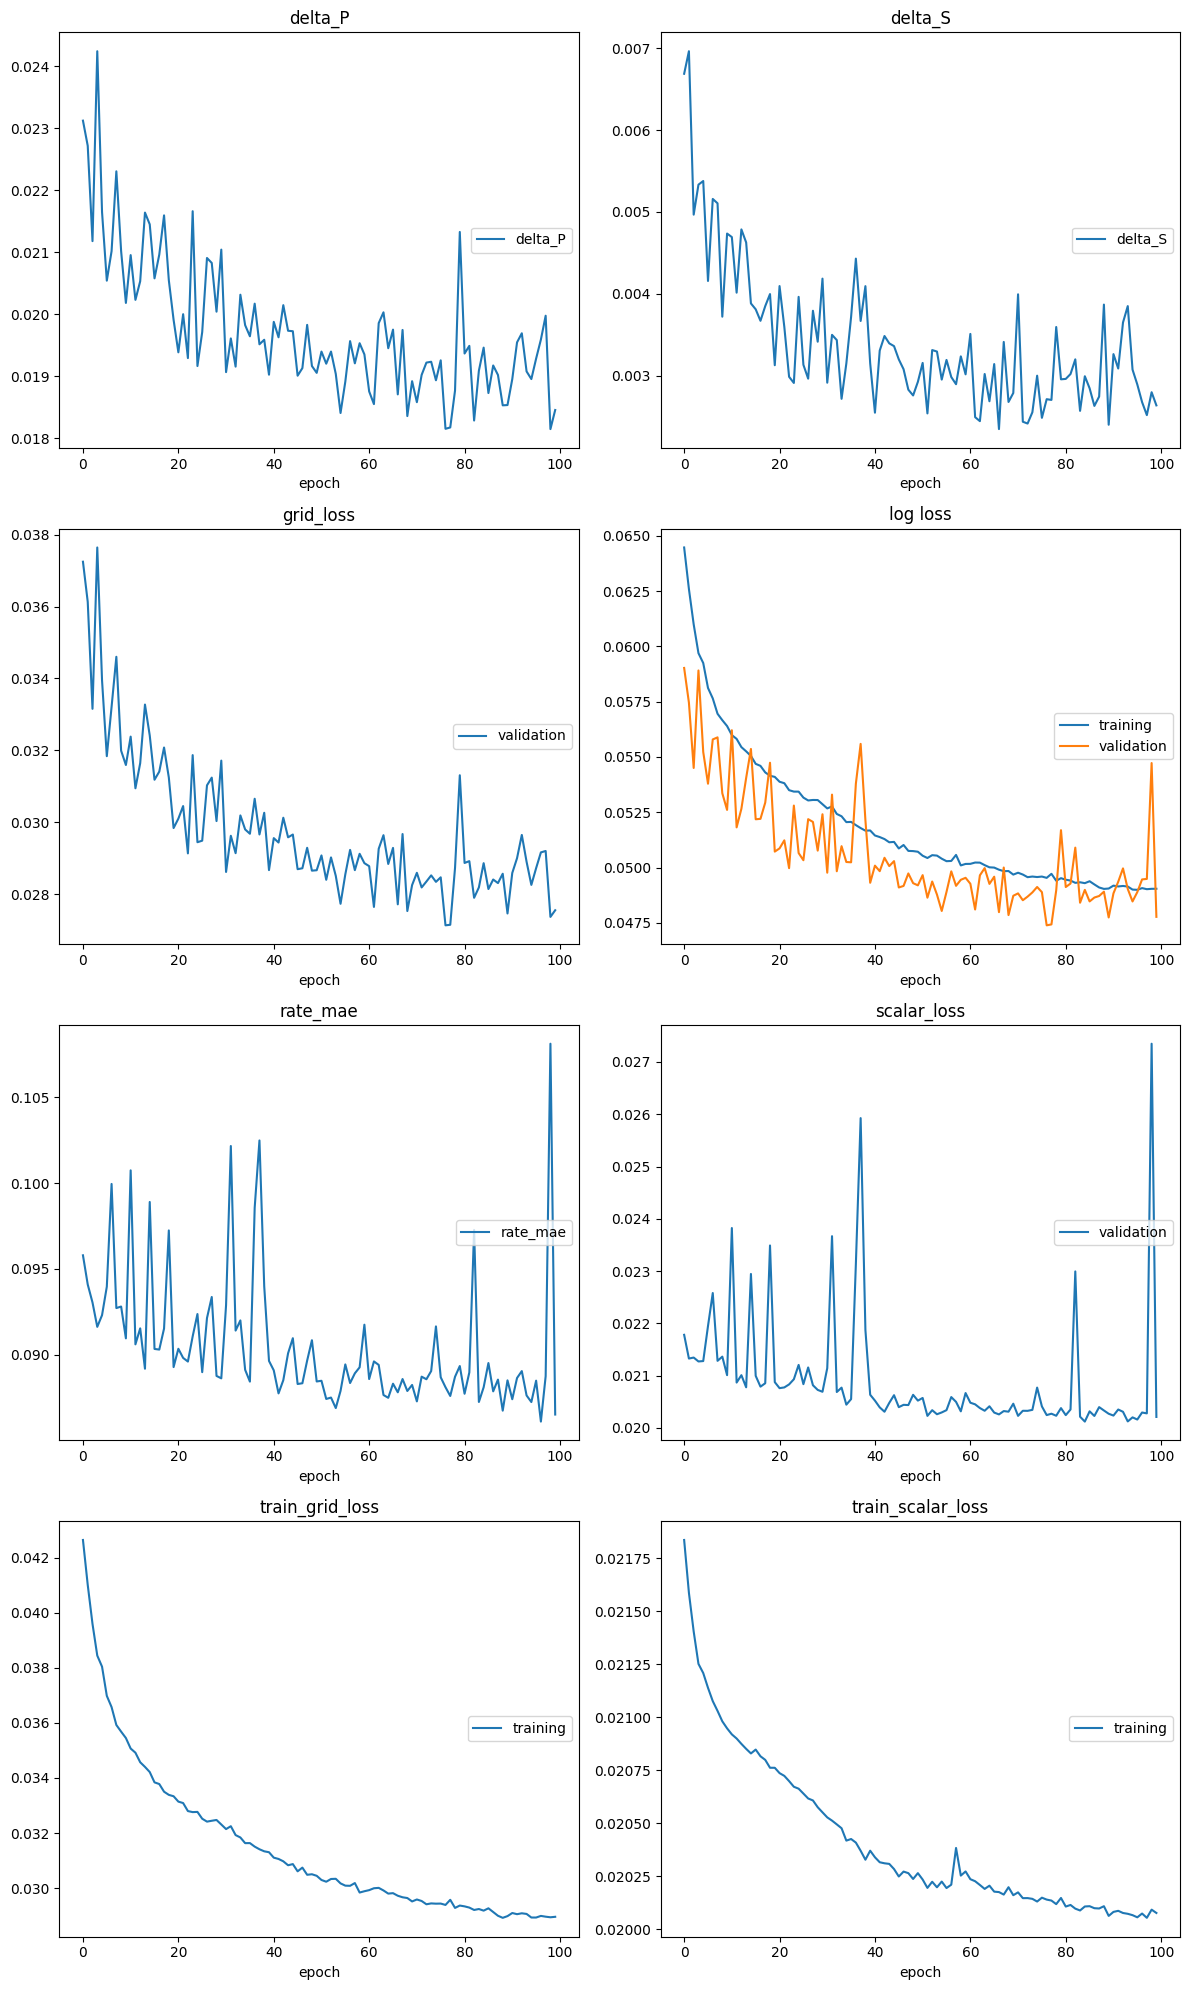

delta_P
	delta_P          	 (min:    0.018, max:    0.024, cur:    0.018)
delta_S
	delta_S          	 (min:    0.002, max:    0.007, cur:    0.003)
grid_loss
	validation       	 (min:    0.027, max:    0.038, cur:    0.028)
log loss
	training         	 (min:    0.049, max:    0.064, cur:    0.049)
	validation       	 (min:    0.047, max:    0.059, cur:    0.048)
rate_mae
	rate_mae         	 (min:    0.086, max:    0.108, cur:    0.087)
scalar_loss
	validation       	 (min:    0.020, max:    0.027, cur:    0.020)
train_grid_loss
	training         	 (min:    0.029, max:    0.043, cur:    0.029)
train_scalar_loss
	training         	 (min:    0.020, max:    0.022, cur:    0.020)


In [ ]:
import json

log_path = "/content/drive/My Drive/tlp25_IRP/Modelling/FiLM_UNET_loss"

liveloss = PlotLosses()

for i in range(1,epochs+1):
  train_loss, train_grid_loss, train_scalar_loss = train(model, optimiser, grid_criterion, scalar_criterion, train_loader, scalar_weight)
  valid_loss, delta_S, delta_P, rate_mae, valid_grid_loss, valid_scalar_loss = valid(
      model, grid_criterion, scalar_criterion, valid_loader, val_dataset, scalar_weight
  )

  logs = {}
  logs["log loss"] = train_loss
  logs["val_log loss"] = valid_loss
  logs["delta_S"] = delta_S
  logs["delta_P"] = delta_P
  logs["rate_mae"] = rate_mae
  logs["train_grid_loss"] = train_grid_loss
  logs["train_scalar_loss"] = train_scalar_loss
  logs["val_grid_loss"] = valid_grid_loss
  logs["val_scalar_loss"] = valid_scalar_loss
  logs["epoch_run2"] = i
  liveloss.update({k: v for k, v in logs.items() if k != "epoch"})
  liveloss.send()

  all_logs.append(logs)

  with open(log_path, "w") as f:
    json.dump(all_logs, f)

  if i % 10 == 0:
     model_save_name = f'FiLM_UNET_epoch_{i}.pth'           # .pt and .pth are common file extensions for saving models in pytorch
     path = f"/content/drive/My Drive/tlp25_IRP/Modelling/{model_save_name}" # use this to store in your Google Drive storage
     torch.save(model.state_dict(), path)
